# CAD226 - Trabalho Final
## Tema 1: Data Lakehouse, Text Mining (PLN) e Dashboard

**Pergunta:** o tom dos documentos oficiais das empresas, somado a preços e balanços, ajuda a prever se a ação sobe no pregão seguinte?

**Como rodar:** *Ambiente de execução > Executar tudo*. O notebook parte da camada **Bronze** já coletada (congelada em 20/11/2026) e refaz Prata, Ouro, modelos e avaliação. Nenhuma senha é necessária.

| Passo | Seção |
|---|---|
| Coleta automatizada e Bronze | 2 |
| Prata (limpeza e datas de disponibilidade) | 3 |
| Sentimento (FinBERT-PT-BR) | 4 |
| Ouro (base integrada) e teste de vazamento | 5 |
| Divisão temporal | 6 |
| Random Forest x LSTM | 7 e 8 |
| Custos, limiar e simulação | 9 |
| Explicabilidade | 10 |
| `run_pipeline` e painel | 11 e 12 |

## 1. Preparação

In [1]:
REPO_URL = "https://github.com/andrevillaca25-code/cad226.git"
TREINAR = True
COLETAR_AO_VIVO = False

import os, subprocess, sys
from pathlib import Path

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    if not Path("/content/cad226").exists():
        if Path("/content/cad226.zip").exists():
            subprocess.run(["unzip", "-q", "/content/cad226.zip", "-d", "/content"], check=True)
        else:
            subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/cad226"], check=True)
    os.chdir("/content/cad226")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif not Path("src").exists():
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Python", sys.version.split()[0], "| pasta", Path.cwd().name)

Python 3.13.2 | pasta cad226


In [2]:
import json, logging, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator
warnings.filterwarnings("ignore")
logging.getLogger("cad226").setLevel(logging.ERROR)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9", "font.size": 9})
AZUL, LARANJA, CINZA = "#1c5cab", "#eb6834", "#898781"

from src import graficos
from src.config import parametros, tickers
from src.storage import lake, controle
from src.processing import precos, fundamentos, textos
from src.nlp import sentimento
from src.features import ouro
from src.evaluation import divisao, metricas, custos, explicabilidade
from src.models import experimento
print("Ativos:", tickers())

Ativos: ['PETR4', 'VALE3', 'ITUB4', 'WEGE3', 'BBAS3', 'ABEV3', 'B3SA3', 'RENT3', 'EMBJ3', 'GGBR4']


## 2. Bronze: dados originais

A Bronze guarda o que veio da fonte, sem interpretar: as contas da CVM ficam como texto, com o hash do arquivo de origem. A gravação é um *upsert* em **Delta Lake** (Parquet + log de transações): repetir a carga não duplica e qualquer versão antiga pode ser relida.

A coleta ao vivo está em `src/ingestion`. Ela fica desligada por padrão para que o resultado seja sempre o mesmo; ligue `COLETAR_AO_VIVO` para ver as fontes sendo consultadas.

In [3]:
if COLETAR_AO_VIVO:
    from src.pipeline.run import coletar
    print("avisos:", coletar(avisar=print))

linhas = []
for pasta in sorted(Path("data/bronze").iterdir()):
    if pasta.is_dir() and not pasta.name.startswith("_"):
        d = lake.ler("bronze", pasta.name)
        linhas.append({"tabela": pasta.name, "linhas": len(d), "colunas": d.shape[1], "versao": lake.versao("bronze", pasta.name)})
display(pd.DataFrame(linhas))
display(lake.ler("bronze", "cadastro")[["ticker", "cnpj", "cd_cvm", "nome", "setor"]])

,tabela,linhas,colunas,versao
0,cadastro,10,7,0
1,cdi,2233,2,0
2,controle,58,8,57
3,cvm_contas,250866,18,22
4,cvm_indice,464,11,19
5,cvm_ipe,7275,14,9
6,cvm_textos,1800,6,22
7,noticias,30,10,2
8,precos,27107,12,10


,ticker,cnpj,cd_cvm,nome,setor
0,ABEV3,07.526.557/0001-00,23264,AMBEV S.A.,Bebidas e Fumo
1,RENT3,16.670.085/0001-55,19739,LOCALIZA RENT A CAR SA,Serviços Transporte e Logística
2,PETR4,33.000.167/0001-01,9512,PETRÓLEO BRASILEIRO S.A. - PETROBRAS,Petróleo e Gás
3,VALE3,33.592.510/0001-54,4170,VALE S.A.,Extração Mineral
4,GGBR4,33.611.500/0001-19,3980,GERDAU S.A.,Metalurgia e Siderurgia
5,WEGE3,84.429.695/0001-11,5410,WEG SA,"Emp. Adm. Part. - Máqs., Equip., Veíc. e Peças"
6,EMBJ3,07.689.002/0001-89,20087,EMBRAER S.A.,"Máquinas, Equipamentos, Veículos e Peças"
7,B3SA3,09.346.601/0001-25,21610,"B3 S.A. - BRASIL, BOLSA, BALCÃO",Bolsas de Valores/Mercadorias e Futuros
8,ITUB4,60.872.504/0001-23,19348,ITAÚ UNIBANCO HOLDING S.A.,Bancos
9,BBAS3,00.000.000/0001-91,1023,BANCO DO BRASIL S.A.,Bancos


In [4]:
c = lake.ler("bronze", "controle")
display(Markdown("**Controle de atualizações** (última coleta de cada fonte)"))
display(c.sort_values("momento").drop_duplicates(["fonte", "alvo"], keep="last").groupby("fonte").agg(alvos=("alvo", "nunique"), ultima=("momento", "max"), ultima_data=("ultima_data", "max"), com_erro=("erro", lambda s: (s != "").sum())))
display(Markdown("**Dado bruto da CVM**, como publicado:"))
display(lake.ler("bronze", "cvm_contas").query("DT_REFER == '2026-09-30' and demonstracao == 'DRE_con'")[["DENOM_CIA", "VERSAO", "ORDEM_EXERC", "DT_INI_EXERC", "CD_CONTA", "DS_CONTA", "VL_CONTA", "ESCALA_MOEDA"]].head(4))

**Controle de atualizações** (última coleta de cada fonte)

,alvos,ultima,ultima_data,com_erro
fonte,,,,
BCB-SGS,1,2026-11-25T18:39:37.840802+00:00,2026-11-24,0
CVM-DFP,10,2026-11-25T18:41:59.102207+00:00,2026-03-12,0
CVM-FCA,1,2026-11-25T18:40:34.374291+00:00,,0
CVM-IPE,10,2026-11-25T18:38:45.995456+00:00,2026-11-18,0
CVM-ITR,10,2026-11-25T18:43:36.373884+00:00,2026-11-12,0
FinBERT-PT-BR,2,2026-11-25T19:52:46.198302+00:00,,0
RSS,3,2026-11-25T18:51:02.291727+00:00,2026-11-25T18:49:08+00:00,0
treino,1,2026-11-25T19:55:28.667282+00:00,,0
yfinance,11,2026-11-25T18:38:56.895487+00:00,2026-11-24,0


**Dado bruto da CVM**, como publicado:

,DENOM_CIA,VERSAO,ORDEM_EXERC,DT_INI_EXERC,CD_CONTA,DS_CONTA,VL_CONTA,ESCALA_MOEDA
1223,BCO BRASIL S.A.,1,ÚLTIMO,2026-01-01,3.01,Receitas de Intermediação Financeira,242664529.0000000000,MIL
1224,BCO BRASIL S.A.,1,ÚLTIMO,2026-07-01,3.02.01,Despesa de Juros,-56737394.0000000000,MIL
1225,BCO BRASIL S.A.,1,ÚLTIMO,2026-01-01,3.03,Resultado Bruto de Intermediação Financeira,74643330.0000000000,MIL
1226,BCO BRASIL S.A.,1,ÚLTIMO,2026-07-01,3.03,Resultado Bruto de Intermediação Financeira,25180021.0000000000,MIL


## 3. Prata: limpeza e data de disponibilidade

Decisões que evitam erro ou vazamento:

- **Calendário.** O Yahoo devolve feriados como pregão. Só vale o dia em que o Ibovespa tem cotação e a maioria dos ativos negociou.
- **Dividendos.** O *Adj Close* da fonte muda todo o passado a cada novo provento. Calculamos o retorno total nós mesmos, para frente.
- **Evento societário.** ITUB4 caiu 18% em 04/10/2021 pela cisão da XP (fato relevante de 02/10/2021). O dia é neutralizado.
- **26/10/2026** (circuit breaker) é real e permanece.
- **Balanços.** A CVM guarda só a última versão. O número vale a partir da data em que *essa versão* foi entregue.
- **Plano de contas.** O lucro é achado pela descrição: é a conta 3.11 na Petrobras e 3.09 no Itaú.

In [5]:
p = precos.construir()
bruto = lake.ler("bronze", "precos")
fora = sorted(set(bruto[bruto.ticker == "PETR4"].data) - set(p[p.ticker == "PETR4"].data.dt.strftime("%Y-%m-%d")))
print(len(p), "linhas | dias descartados como falsos pregões:", fora)
display(p[p.ticker == "B3SA3"].set_index("data").loc["2026-10-22":"2026-10-28", ["abertura", "fechamento", "ret", "ret_abertura", "ret_intradia"]])

27005 linhas | dias descartados como falsos pregões: ['2017-05-29', '2017-06-15', '2017-09-07', '2017-10-12', '2017-11-02', '2017-11-15', '2017-11-20', '2017-12-25', '2017-12-29', '2018-01-25']


,abertura,fechamento,ret,ret_abertura,ret_intradia
data,,,,,
2026-10-22,23.3000,23.2500,-0.0111,-0.0275,-0.0021
2026-10-23,23.2000,23.6500,0.0172,-0.0043,0.0194
2026-10-26,11.8300,15.0700,-0.3628,-0.4901,0.2739
2026-10-27,15.4400,15.4000,0.0219,0.3052,-0.0026
2026-10-28,15.2300,14.6900,-0.0461,-0.0136,-0.0355


In [6]:
f = fundamentos.construir()
display(f[f.periodo == "2026-09-30"].set_index("ticker")[["disponivel_em", "versao", "receita_12m", "lucro_liquido_12m", "ebitda_12m", "patrimonio_liquido", "divida_bruta", "roe_12m", "alavancagem"]].round(2))
print("Documentos reapresentados:", int(f.reapresentado.sum()), "de", len(f), "| atraso mediano entre período e divulgação:", int((f.disponivel_em - f.periodo).dt.days.median()), "dias")

,disponivel_em,versao,receita_12m,lucro_liquido_12m,ebitda_12m,patrimonio_liquido,divida_bruta,roe_12m,alavancagem
ticker,,,,,,,,,
ABEV3,2026-10-29,1,89015.6000,16256.0600,29606.4100,91441.9500,2714.7600,0.1800,0.3500
B3SA3,2026-11-12,2,12309.4100,5712.1000,7760.1600,18905.0100,14962.3200,0.3000,0.6200
BBAS3,2026-11-11,1,328107.0000,14148.8300,NaN,191896.8500,NaN,0.0700,0.9200
EMBJ3,2026-11-10,1,45328.1500,2105.8100,5690.2300,20044.5700,11936.4300,0.1100,0.7200
GGBR4,2026-10-26,1,70251.1100,2748.7500,9787.7500,54848.2400,13729.2300,0.0500,0.3500
ITUB4,2026-11-03,1,398874.0000,48613.0000,NaN,239262.0000,NaN,0.2000,0.9300
PETR4,2026-11-10,1,589940.0000,140692.0000,289816.0000,505631.0000,362505.0000,0.2800,0.6200
RENT3,2026-11-05,1,47899.3700,4288.8200,15627.3600,27560.1900,45315.7100,0.1600,0.7000
VALE3,2026-10-29,2,215830.0000,556.0000,43646.0000,199718.0000,93944.0000,0.0000,0.5600


Documentos reapresentados: 55 de 385 | atraso mediano entre período e divulgação: 38 dias


In [7]:
t = textos.construir()
display(t.groupby("ticker").agg(documentos=("doc_id", "size"), texto_integral=("nivel_texto", lambda s: (s == "integral").sum()), primeiro=("entregue_em", "min"), ultimo=("entregue_em", "max")))
print("Limitações registradas:", t[t.limitacao != ""].limitacao.value_counts().to_dict())

,documentos,texto_integral,primeiro,ultimo
ticker,,,,
ABEV3,98,27,2017-03-02,2026-10-29
B3SA3,417,73,2017-01-06,2026-11-12
BBAS3,712,166,2017-01-07,2026-11-11
EMBJ3,597,80,2017-01-13,2026-11-10
GGBR4,230,57,2017-01-13,2026-11-18
ITUB4,638,100,2017-01-02,2026-11-03
PETR4,2433,605,2017-01-04,2026-11-17
RENT3,313,117,2017-01-23,2026-11-06
VALE3,1074,229,2017-01-03,2026-11-10


Limitações registradas: {'so assunto (categoria)': 5330, 'sem camada de texto': 1}


## 4. PLN: sentimento

**Modelo:** FinBERT-PT-BR (BERTimbau ajustado a notícias financeiras brasileiras), versão fixada. Modelos em inglês foram descartados porque os documentos são em português. Para cada texto: probabilidade de positivo, negativo e neutro; o escore é `p_pos - p_neg`.

Os escores já calculados estão gravados com a versão do modelo; só textos novos são pontuados. Como conferência, um **dicionário** curto e auditável.

> Tom do texto não é previsão de retorno. "Lucro recorde" pode estar no preço há semanas.

In [8]:
s = sentimento.atualizar()
x = t.merge(s, on="hash_conteudo")
print("modelo:", s.modelo.iloc[0], "| textos pontuados:", len(x))
display(pd.crosstab(x.categoria, x.classe, margins=True))
con = x[x.dicionario != 0]
print(f"Dicionário encontrou termos em {len(con)/len(x):.0%} dos textos; correlação com o escore do FinBERT nesses textos: {con[['escore','dicionario']].corr().iloc[0,1]:.2f}")
for classe in ("positivo", "negativo", "neutro"):
    e = x[(x.classe == classe) & (x.nivel_texto == "integral")].nlargest(2, {"positivo": "p_pos", "negativo": "p_neg", "neutro": "p_neu"}[classe])
    for r in e.itertuples():
        display(Markdown(f"- **{classe}** ({r.escore:+.2f}) {r.ticker}, {r.entregue_em:%d/%m/%Y}: {r.assunto[:120]}"))

modelo: lucas-leme/FinBERT-PT-BR@c3bf75c8 | textos pontuados: 6803


classe,negativo,neutro,positivo,All
categoria,,,,
Comunicado ao Mercado,714,3924,692,5330
Fato Relevante,234,900,339,1473
All,948,4824,1031,6803


Dicionário encontrou termos em 29% dos textos; correlação com o escore do FinBERT nesses textos: 0.51


- **positivo** (+0.91) PETR4, 10/11/2026: Petrobras atualiza projeções operacionais e financeiras para 2026

- **positivo** (+0.91) EMBJ3, 05/11/2021: Modificação de Projeções Divulgadas

- **negativo** (-0.91) ITUB4, 04/05/2020: Projeções

- **negativo** (-0.91) EMBJ3, 25/04/2020: Parceria Estratégica Embraer e Boeing

- **neutro** (+0.01) PETR4, 06/11/2018: Petrobras aprova pagamento de Juros sobre o Capital Próprio

- **neutro** (+0.01) RENT3, 12/12/2019: 1. Juros sobre capital próprio||2. Aumento de capital com bonificação em ações

**O tom carrega informação?** Estudo de evento feito **só no período de treino**: retorno do ativo menos o do Ibovespa no primeiro pregão em que o documento já era público. O intervalo é de 95%.

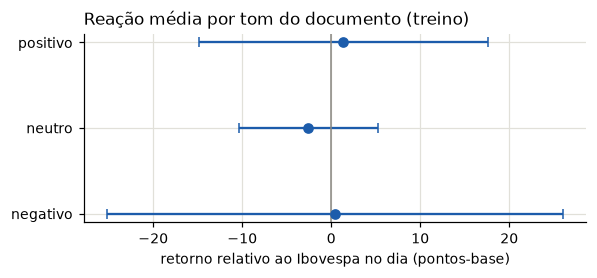

,size,media_bps,erro_bps
classe,,,
negativo,699,0.4245,25.6652
neutro,3193,-2.5583,7.8577
positivo,717,1.3674,16.1966


In [9]:
base_prev = ouro.construir()
tc = lake.ler("gold", "textos_classificados").dropna(subset=["data"])
tc["data"] = pd.to_datetime(tc.data)
ev = tc.merge(base_prev[["ticker", "data", "rel1"]], on=["ticker", "data"])
ev = ev[ev.data <= parametros()["divisao"]["treino"][1]]
est = ev.groupby("classe").rel1.agg(["mean", "std", "size"])
est["erro"] = 1.96 * est["std"] / np.sqrt(est["size"])
est = est.loc[["negativo", "neutro", "positivo"]]
fig, ax = plt.subplots(figsize=(5.5, 2.6))
ax.errorbar(est["mean"] * 1e4, est.index, xerr=est.erro * 1e4, fmt="o", color=AZUL, capsize=3)
ax.axvline(0, color=CINZA, lw=1); ax.set_xlabel("retorno relativo ao Ibovespa no dia (pontos-base)"); ax.set_title("Reação média por tom do documento (treino)", loc="left"); plt.tight_layout(); plt.show()
display(est.assign(media_bps=est["mean"] * 1e4, erro_bps=est.erro * 1e4)[["size", "media_bps", "erro_bps"]])

## 5. Ouro: base integrada

Uma linha por ativo e pregão. **A linha de `t` só tem informação conhecida até o fechamento de `t`**; o alvo é a direção do retorno de `t+1`.

- Alvo = 1 se o retorno for **maior que zero**; retorno igual a zero conta como 0, porque não paga os custos.
- Documento entregue em `D` conta a partir do pregão **seguinte** a `D` (a CVM não publica a hora).
- "Sem documento" tem indicador próprio, para não ser confundido com texto neutro.

In [10]:
base = ouro.base_modelagem()
print(base.shape, base.data.min().date(), "a", base.data.max().date())
display(pd.DataFrame([{"grupo": g, "variáveis": ", ".join(v)} for g, v in ouro.GRUPOS.items()]).style.hide(axis="index"))
display(base[base.ticker == "PETR4"].tail(3).T)

(22540, 42) 2017-10-20 a 2026-11-19


grupo,variáveis
Preço e volume,"r1, r5, r21, vol21, vol5_21, volume_rel, amplitude, intradia, rsi14, dist_mm20, dist_mm50, dist_mm200"
Mercado,"ibov_r1, ibov_r5, ibov_vol21, rel1, rel5"
Texto,"n_docs, n_docs5, n_docs21, sent_dia, sent5, sent21, tem_doc5, pregoes_sem_doc"
Fundamentos,"roe_12m, margem_liquida_12m, alavancagem, cresc_receita, cresc_lucro, dias_desde_balanco"


,15775,15776,15777
ticker,PETR4,PETR4,PETR4
data,2026-11-17 00:00:00,2026-11-18 00:00:00,2026-11-19 00:00:00
data_alvo,2026-11-18 00:00:00,2026-11-19 00:00:00,2026-11-23 00:00:00
alvo,0.0000,0.0000,0.0000
ret_prox,-0.0184,-0.0116,-0.0321
ret_exec,-0.0039,-0.0299,-0.0317
ret_intradia_prox,-0.0121,-0.0198,-0.0220
fechamento,43.9800,43.1700,42.6700
volume,23690600.0000,30393500.0000,39268400.0000
balanco_periodo,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00


**Teste de vazamento.** Adulteramos todos os preços depois de 30/06/2023 e reconstruímos o Ouro. Se alguma variável anterior mudasse, haveria informação do futuro.

In [11]:
corte = pd.Timestamp("2023-06-30")
falso = lake.ler("silver", "precos"); falso["data"] = pd.to_datetime(falso.data)
for col in ("ret", "ret_log", "indice_rt", "volume", "maxima", "minima", "fechamento", "abertura", "ret_intradia"):
    falso.loc[falso.data > corte, col] = falso.loc[falso.data > corte, col] * 3 + 0.01
novo = ouro.construir(precos=falso, gravar=False).set_index(["ticker", "data"]).sort_index()[ouro.NUMERICAS]
orig = base.set_index(["ticker", "data"]).sort_index()[ouro.NUMERICAS]
antes = orig.index[orig.index.get_level_values("data") <= corte]
depois = orig.index[orig.index.get_level_values("data") > corte]
print("maior diferença antes do corte:", float((novo.loc[antes] - orig.loc[antes]).abs().max().max()))
print("linhas alteradas depois do corte:", f"{(~np.isclose(novo.loc[depois], orig.loc[depois], equal_nan=True)).any(axis=1).mean():.0%}")

maior diferença antes do corte: 0.0
linhas alteradas depois do corte: 100%


## 6. Divisão temporal

- **Treino** 2018-2023: hiperparâmetros por `TimeSeriesSplit` com 5 folds e embargo de 5 pregões.
- **Validação** 2024: usada **só** para ajustar o limiar de decisão.
- **Teste** 2025 a 18/11/2026: usado uma única vez.

O `TimeSeriesSplit` corre sobre **datas únicas**. Se corresse sobre as linhas, o mesmo pregão ficaria dos dois lados, porque a base empilha 10 ativos.

,bloco,inicio,fim,pregoes,observacoes,altas_%
0,treino,2018-01-02,2023-12-28,1486,14859,50.0000
1,validacao,2024-01-02,2024-12-30,251,2510,48.0000
2,teste,2025-01-02,2026-11-18,470,4700,51.5000
3,fold 1 - ajuste,2018-01-02,2019-01-02,246,2460,49.8000
4,fold 1 - validação,2019-01-10,2020-01-08,247,2470,51.0000
5,fold 2 - ajuste,2018-01-02,2019-12-30,493,4930,50.7000
6,fold 2 - validação,2020-01-09,2021-01-07,247,2470,51.1000
7,fold 3 - ajuste,2018-01-02,2020-12-29,740,7400,50.6000
8,fold 3 - validação,2021-01-08,2022-01-06,247,2469,47.2000
9,fold 4 - ajuste,2018-01-02,2021-12-29,987,9869,49.8000


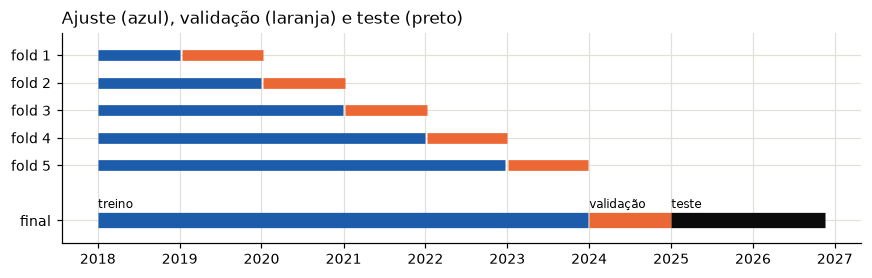

In [12]:
q = divisao.quadro(base); display(q)
m = divisao.mascaras(base)
fig, ax = plt.subplots(figsize=(8, 2.6))
for i, (a, v) in enumerate(divisao.folds(base, m["treino"])):
    for mask, cor in ((a, AZUL), (v, LARANJA)):
        d = base[mask].data; ax.plot([d.min(), d.max()], [6 - i] * 2, lw=7, color=cor, solid_capstyle="butt")
for nome, cor in (("treino", AZUL), ("validacao", LARANJA), ("teste", "#0b0b0b")):
    d = base[m[nome]].data; ax.plot([d.min(), d.max()], [0] * 2, lw=10, color=cor, solid_capstyle="butt"); ax.text(d.min(), 0.45, nome.replace("validacao", "validação"), fontsize=8)
ax.set_yticks([6 - i for i in range(5)] + [0]); ax.set_yticklabels([f"fold {i}" for i in range(1, 6)] + ["final"]); ax.set_ylim(-.8, 6.8)
ax.set_title("Ajuste (azul), validação (laranja) e teste (preto)", loc="left"); plt.tight_layout(); plt.show()

## 7. Duelo de modelos

- **Random Forest**: média de 400 árvores rasas. Não precisa de escala e captura interações.
- **LSTM** (PyTorch): lê os últimos 20 pregões do ativo como sequência. Parada antecipada em cada fold; no ajuste final usa o número mediano de épocas e faz a média de 3 sementes.
- **Linhas de base**: regressão logística e classe majoritária.
- **Ablação**: os dois modelos também são treinados **sem** as variáveis de texto.

Mediana e escala são aprendidas só no treino.

In [13]:
pacote = None if TREINAR else experimento.carregar()
if pacote is None:
    experimento.executar()
    pacote = experimento.carregar()
modelos, res = pacote

Random Forest: {'max_depth': 3, 'min_samples_leaf': 200}


LSTM: {'ocultas': 32, 'dropout': 0.5, 'epocas': 2}


Random Forest sem texto: {'max_depth': 3, 'min_samples_leaf': 200}


LSTM sem texto: {'ocultas': 32, 'dropout': 0.5, 'epocas': 2}


Random Forest: AUC validação 0.5128 limiar 0.515


LSTM: AUC validação 0.5011 limiar 0.531


Random Forest sem texto: AUC validação 0.5065 limiar 0.530


LSTM sem texto: AUC validação 0.4911 limiar 0.535


Regressão logística: AUC validação 0.4901 limiar 0.615


Classe majoritária: AUC validação 0.5000 limiar 0.500


In [14]:
for nome in ("Random Forest", "LSTM"):
    cv = pd.DataFrame(res["cv"][nome]); chaves = [c for c in cv.columns if c not in ("fold", "perda", "auc", "epoca")]
    display(Markdown(f"**{nome}** - média dos 5 folds (escolhido: `{res['modelos'][nome]['hiperparametros']}`)"))
    display(cv.groupby(chaves)[["perda", "auc"]].agg(["mean", "std"]).round(4))
print("Perda logarítmica de um chute de 50%:", round(np.log(2), 4))

**Random Forest** - média dos 5 folds (escolhido: `{'max_depth': 3, 'min_samples_leaf': 200}`)

perda           auc       
                             mean    std   mean    std
max_depth min_samples_leaf                            
3         50               0.6930 0.0027 0.5157 0.0235
          200              0.6929 0.0027 0.5176 0.0251
6         50               0.6937 0.0036 0.5140 0.0221
          200              0.6934 0.0033 0.5148 0.0234
10        50               0.6946 0.0039 0.5110 0.0198
          200              0.6935 0.0034 0.5140 0.0228

**LSTM** - média dos 5 folds (escolhido: `{'ocultas': 32, 'dropout': 0.5, 'epocas': 2}`)

perda           auc       
                  mean    std   mean    std
ocultas dropout                            
16      0.2000  0.6939 0.0014 0.5070 0.0154
        0.5000  0.6938 0.0011 0.5050 0.0126
32      0.2000  0.6940 0.0019 0.5082 0.0206
        0.5000  0.6937 0.0019 0.5105 0.0209

Perda logarítmica de um chute de 50%: 0.6931


## 8. Resultados fora da amostra

In [15]:
cols = ["accuracy", "precision", "recall", "f1", "mcc", "auc", "brier", "previu_alta_%"]
tab = pd.DataFrame({n: r["teste_0.5"] for n, r in res["modelos"].items()}).T
display(Markdown("**Teste, limiar 0,5**")); display(tab[cols].astype(float).round(4))
display(Markdown("**Intervalos de 95%** (bootstrap em blocos de 5 pregões, que respeita a dependência entre ativos e dias)"))
display(pd.DataFrame({n: {"acurácia": r["teste_0.5"]["accuracy"], "IC acurácia": r["teste_0.5"]["accuracy_ic"], "AUC": r["teste_0.5"]["auc"], "IC AUC": r["teste_0.5"]["auc_ic"]} for n, r in res["modelos"].items()}).T)
display(Markdown("**Diferenças entre modelos** (o intervalo que contém zero indica empate)"))
display(pd.DataFrame(res["comparacoes"]).T)

**Teste, limiar 0,5**

,accuracy,precision,recall,f1,mcc,auc,brier,previu_alta_%
Random Forest,0.4909,0.5114,0.2496,0.3355,-0.0040,0.4910,0.2506,25.1277
LSTM,0.4921,0.5086,0.4025,0.4494,-0.0104,0.4907,0.2507,40.7447
Random Forest sem texto,0.4926,0.5141,0.2645,0.3492,-0.0010,0.4917,0.2506,26.4894
LSTM sem texto,0.4851,0.5000,0.4174,0.4550,-0.0259,0.4850,0.2507,42.9787
Regressão logística,0.4949,0.5103,0.4707,0.4897,-0.0087,0.4987,0.2511,47.4894
Classe majoritária,0.4851,0.0000,0.0000,0.0000,0.0000,0.5000,0.2500,0.0000


**Intervalos de 95%** (bootstrap em blocos de 5 pregões, que respeita a dependência entre ativos e dias)

,acurácia,IC acurácia,AUC,IC AUC
Random Forest,0.4909,"[0.468, 0.512]",0.4910,"[0.47, 0.5146]"
LSTM,0.4921,"[0.4743, 0.513]",0.4907,"[0.468, 0.5171]"
Random Forest sem texto,0.4926,"[0.4697, 0.5144]",0.4917,"[0.471, 0.5162]"
LSTM sem texto,0.4851,"[0.4646, 0.5053]",0.4850,"[0.4609, 0.5107]"
Regressão logística,0.4949,"[0.4783, 0.5117]",0.4987,"[0.4797, 0.5207]"
Classe majoritária,0.4851,"[0.4583, 0.5096]",0.5000,"[0.5, 0.5]"


**Diferenças entre modelos** (o intervalo que contém zero indica empate)

,dif_accuracy,dif_accuracy_ic,dif_auc,dif_auc_ic
LSTM x Random Forest,0.0013,"[-0.0175, 0.0249]",-0.0003,"[-0.0164, 0.0177]"
Random Forest x Random Forest sem texto,-0.0017,"[-0.0074, 0.0049]",-0.0007,"[-0.0075, 0.0072]"
LSTM x LSTM sem texto,0.0070,"[-0.003, 0.0187]",0.0057,"[-0.0049, 0.0165]"
Random Forest x Regressão logística,-0.0040,"[-0.0268, 0.0154]",-0.0077,"[-0.0265, 0.0085]"


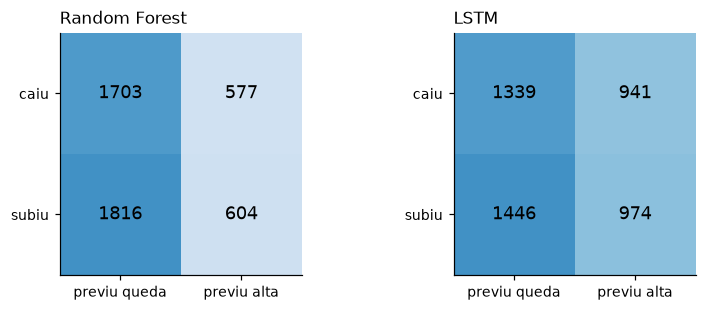

In [16]:
fig, eixos = plt.subplots(1, 2, figsize=(7.5, 2.9))
for ax, nome in zip(eixos, ("Random Forest", "LSTM")):
    r = res["modelos"][nome]["teste_0.5"]; z = np.array([[r["VN"], r["FP"]], [r["FN"], r["VP"]]])
    ax.imshow(z, cmap="Blues", vmin=0, vmax=z.max() * 1.6); ax.grid(False)
    for (i, j), v in np.ndenumerate(z): ax.text(j, i, v, ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1], ["previu queda", "previu alta"]); ax.set_yticks([0, 1], ["caiu", "subiu"]); ax.set_title(nome, loc="left")
plt.tight_layout(); plt.show()

In [17]:
prev = lake.ler("gold", "previsoes"); prev["data"] = pd.to_datetime(prev.data)
pt = prev[prev.data >= parametros()["divisao"]["teste"][0]].dropna(subset=["alvo"])
por = pd.DataFrame({n: pt.groupby("ticker").apply(lambda g: ((g[n] > .5) == g.alvo).mean()) for n in ("Random Forest", "LSTM")})
por["sempre alta"] = pt.groupby("ticker").alvo.mean()
display(Markdown("**Acurácia por ativo no teste**")); display(por.round(3))

**Acurácia por ativo no teste**

,Random Forest,LSTM,sempre alta
ticker,,,
ABEV3,0.5120,0.4880,0.5220
B3SA3,0.5050,0.5070,0.5010
BBAS3,0.4610,0.4650,0.4900
EMBJ3,0.4880,0.4880,0.5290
GGBR4,0.5220,0.5160,0.4970
ITUB4,0.4860,0.4780,0.5410
PETR4,0.4710,0.4800,0.5410
RENT3,0.4900,0.5100,0.4990
VALE3,0.4650,0.5070,0.5200


## 9. Fricções operacionais

1. **Matriz de custos**, estimada no treino: falso positivo perde a queda média mais ida e volta de custos; falso negativo deixa de ganhar a alta média líquida.
2. **Limiar** escolhido na validação para minimizar esse custo.
3. **Simulação**: sinal depois do fechamento de `t`, compra na **abertura** de `t+1`, peso igual, caixa em CDI, sem venda a descoberto (logo, sem aluguel).

Os custos por lado são **hipóteses** do grupo (3 bps de tarifas + 5 bps de spread e slippage), com análise de sensibilidade.

Matriz de custos: {'FP': '1.822%', 'FN': '1.686%', 'VP': '0.000%', 'VN': '0.000%'} | limiar teórico: 0.5195


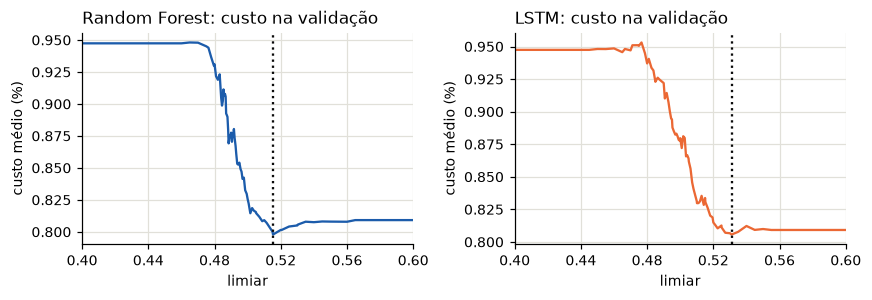

,limiar,"custo validação 0,5 (%)",custo validação ajustado (%),"custo teste 0,5 (%)",custo teste ajustado (%)
Random Forest,0.5153,0.8256,0.7979,0.8750,0.8755
LSTM,0.5310,0.8796,0.8057,0.8834,0.8785
Random Forest sem texto,0.5300,0.8337,0.8027,0.8729,0.8778
LSTM sem texto,0.5350,0.8778,0.8054,0.8973,0.8716
Regressão logística,0.6150,0.8962,0.8092,0.8832,0.8687
Classe majoritária,0.5000,0.8092,0.8092,0.8679,0.8679


In [18]:
print("Matriz de custos:", {k: f"{v:.3%}" for k, v in res["matriz_custos"].items()}, "| limiar teórico:", round(res["limiar_teorico"], 4))
fig, eixos = plt.subplots(1, 2, figsize=(8, 2.8))
for ax, nome, cor in zip(eixos, ("Random Forest", "LSTM"), (AZUL, LARANJA)):
    c = custos.curva_limiar(base.alvo.to_numpy()[m["validacao"]], prev[nome].to_numpy()[m["validacao"]], res["matriz_custos"])
    ax.plot(c.limiar, c.custo * 100, color=cor); ax.axvline(res["modelos"][nome]["limiar"], color="#0b0b0b", ls=":"); ax.set_title(f"{nome}: custo na validação", loc="left"); ax.set_xlabel("limiar"); ax.set_ylabel("custo médio (%)"); ax.set_xlim(.4, .6); ax.xaxis.set_major_locator(MaxNLocator(5))
plt.tight_layout(); plt.show()
display(pd.DataFrame({n: {"limiar": r["limiar"], "custo validação 0,5": r["validacao_0.5"]["custo"], "custo validação ajustado": r["validacao"]["custo"], "custo teste 0,5": r["teste_0.5"]["custo"], "custo teste ajustado": r["teste"]["custo"]} for n, r in res["modelos"].items()}).T.mul([1, 100, 100, 100, 100]).round(4).rename(columns=lambda c: c + (" (%)" if "custo" in c else "")))

In [19]:
sim = {f"{n} | {k}": v for n in ("Random Forest", "LSTM", "Regressão logística") for k, v in res["modelos"][n]["simulacao"].items()}
sim.update(res["referencias"])
display(pd.DataFrame(sim).T.astype(float).round(2))
display(Markdown("**Retorno anual (%) por custo de cada lado, em pontos-base**"))
display(pd.DataFrame({n: r["sensibilidade"] for n, r in res["modelos"].items()}).T.astype(float).round(2))

,retorno_total_%,retorno_aa_%,volatilidade_aa_%,sharpe_vs_cdi,queda_maxima_%,giro_diario_%,exposicao_media_%
"Random Forest | limiar 0,5",-2.7300,-1.4800,10.1900,-1.4100,-17.3800,28.8300,25.1300
Random Forest | limiar ajustado,14.0400,7.3000,6.8500,-0.8900,-8.5800,12.1100,11.1100
Random Forest | fechamento (impossível),17.2000,8.8800,8.9300,-0.5000,-7.6500,28.8300,25.1300
"Random Forest | limiar 0,5 sem 26/10/2026",3.2100,1.7200,9.0000,-1.2500,-12.3300,28.5700,25.0400
"LSTM | limiar 0,5",-3.1200,-1.6900,14.3100,-0.9800,-20.8600,21.1500,40.7400
LSTM | limiar ajustado,14.5000,7.5300,3.6900,-1.6400,-6.2100,3.6200,2.9100
LSTM | fechamento (impossível),18.4700,9.5100,10.5300,-0.3500,-10.5400,21.1500,40.7400
"LSTM | limiar 0,5 sem 26/10/2026",9.8600,5.2000,10.0900,-0.7700,-13.1700,21.0700,40.6200
"Regressão logística | limiar 0,5",9.9500,5.2200,14.8500,-0.4800,-15.8400,27.9600,47.4900
Regressão logística | limiar ajustado,27.5400,13.9300,0.4300,-0.7800,-0.5200,0.2600,0.1300


**Retorno anual (%) por custo de cada lado, em pontos-base**

,0,4,8,15,30
Random Forest,4.4200,1.4300,-1.4800,-6.3600,-16.0400
LSTM,2.6000,0.4300,-1.6900,-5.2900,-12.5700
Random Forest sem texto,0.3700,-2.8500,-5.9600,-11.1800,-21.4100
LSTM sem texto,2.1400,-0.0100,-2.1300,-5.7200,-12.9800
Regressão logística,11.3200,8.2300,5.2200,0.1600,-9.8900
Classe majoritária,14.3100,14.3100,14.3100,14.3100,14.3100


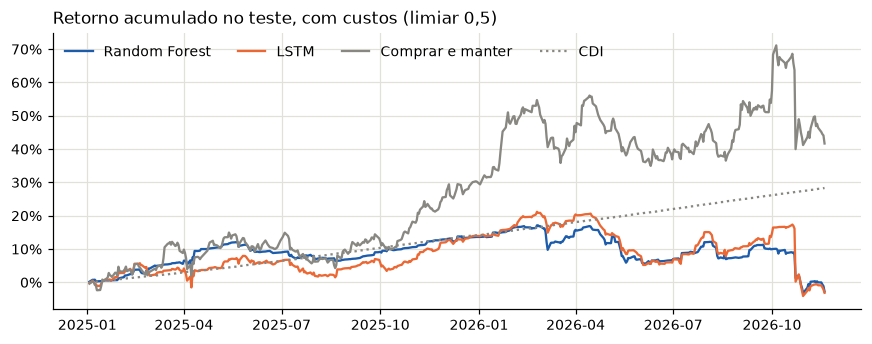

In [20]:
bt = base[m["teste"]]
fig, ax = plt.subplots(figsize=(8, 3.2))
for nome, cor in (("Random Forest", AZUL), ("LSTM", LARANJA)):
    c = custos.simular(bt, prev[nome].to_numpy()[m["teste"]] > .5); ax.plot(c.data_execucao, (1 + c.ret).cumprod() - 1, color=cor, label=nome)
for rot, sinal, ls in (("Comprar e manter", np.ones(len(bt), bool), "-"), ("CDI", np.zeros(len(bt), bool), ":")):
    c = custos.simular(bt, sinal); ax.plot(c.data_execucao, (1 + c.ret).cumprod() - 1, color=CINZA, ls=ls, label=rot)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.legend(frameon=False, ncol=4, loc="upper left"); ax.set_title("Retorno acumulado no teste, com custos (limiar 0,5)", loc="left"); plt.tight_layout(); plt.show()

## 10. Explicabilidade

,queda_auc,desvio
grupo,,
Fundamentos,-0.0004,0.0006
Texto,-0.0001,0.0033
Mercado,-0.0091,0.0058
Preço e volume,-0.0041,0.0042


,queda_auc,desvio
grupo,,
Fundamentos,-0.0003,0.0013
Texto,0.0019,0.0030
Mercado,-0.0052,0.0049
Preço e volume,-0.0033,0.0048


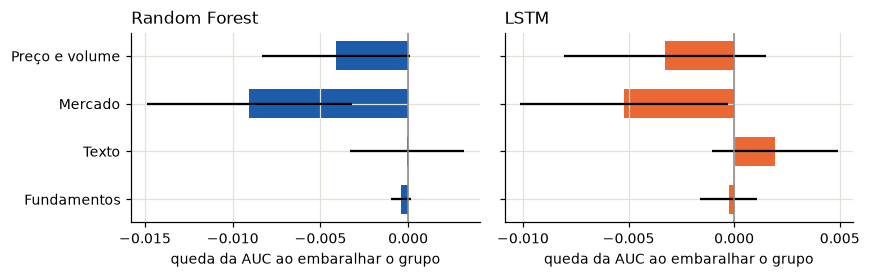

In [21]:
fig, eixos = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
for ax, nome, cor in zip(eixos, ("Random Forest", "LSTM"), (AZUL, LARANJA)):
    imp = explicabilidade.permutacao_grupos(modelos[nome], base, m["teste"]).set_index("grupo").loc[list(ouro.GRUPOS)[::-1]]
    ax.barh(imp.index, imp.queda_auc, xerr=imp.desvio, color=cor, height=.6); ax.axvline(0, color=CINZA, lw=1); ax.set_title(nome, loc="left"); ax.set_xlabel("queda da AUC ao embaralhar o grupo"); ax.xaxis.set_major_locator(MaxNLocator(4))
    display(imp.round(4))
plt.tight_layout(); plt.show()

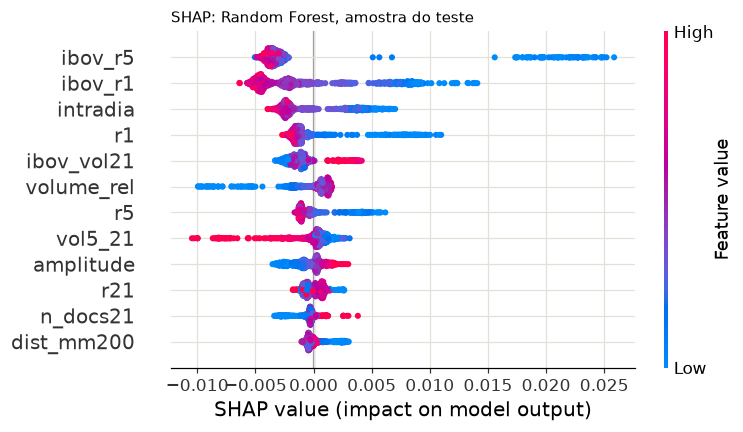

In [22]:
import shap
valores, amostra = explicabilidade.shap_floresta(modelos["Random Forest"], base, m["teste"])
shap.summary_plot(valores, amostra, max_display=12, show=False, plot_size=(7, 4)); plt.title("SHAP: Random Forest, amostra do teste", loc="left", fontsize=10); plt.tight_layout(); plt.show()

## 11. `run_pipeline(ticker, period)`

A mesma função alimenta o painel: identifica o ativo, atualiza só o necessário, refaz o que mudou, recupera os modelos e devolve tudo pronto.

In [23]:
from src.pipeline.run import run_pipeline
r = run_pipeline("PETR4", "1 ano", atualizar=COLETAR_AO_VIVO)
print(r["cadastro"]["nome"], "|", len(r["precos"]), "pregões |", len(r["textos"]), "documentos |", r["proxima"])
graficos.precos(r["precos"], "PETR4").show(renderer="colab" if EM_COLAB else "notebook_connected")

PETRÓLEO BRASILEIRO S.A. - PETROBRAS | 252 pregões | 2433 documentos | {'data_sinal': Timestamp('2026-11-24 00:00:00'), 'Random Forest': {'probabilidade': 0.5297054253790523, 'limiar': 0.5153, 'sinal': 'alta'}, 'LSTM': {'probabilidade': 0.5212850173314413, 'limiar': 0.531, 'sinal': 'sem sinal'}}


## 12. Painel

A célula abaixo inicia o Streamlit e mostra o painel em uma janela dentro do notebook e em um link para nova aba. **No Colab, não use o endereço `localhost` que o Streamlit imprime**: ele aponta para a máquina do Colab. A primeira abertura leva cerca de 30 segundos.

Fora do Colab: `streamlit run dashboard/app.py`.

In [24]:
import time
import urllib.request

PORTA = 8501
LOG = Path("/content/streamlit.log") if EM_COLAB else Path("streamlit.log")


def painel_no_ar() -> bool:
    try:
        return urllib.request.urlopen(f"http://localhost:{PORTA}/_stcore/health", timeout=2).status == 200
    except Exception:
        return False


if not painel_no_ar():
    os.environ["CAD226_COLETAR"] = "0"   # o painel usa o Lakehouse congelado; não consulta as fontes ao abrir
    subprocess.Popen([sys.executable, "-m", "streamlit", "run", "dashboard/app.py",
                      "--server.port", str(PORTA), "--server.headless", "true",
                      "--server.enableCORS", "false", "--server.enableXsrfProtection", "false",   # necessários atrás do proxy do Colab
                      "--browser.gatherUsageStats", "false"],
                     stdout=open(LOG, "w"), stderr=subprocess.STDOUT)
    for _ in range(90):
        if painel_no_ar():
            break
        time.sleep(1)
    else:
        print(LOG.read_text()[-3000:])
        raise RuntimeError("O painel não iniciou em 90 segundos; o log está acima.")

if EM_COLAB:
    from google.colab import output
    print("Painel no ar. Use o link ou a janela abaixo; o endereço 'localhost' que o Streamlit imprime não funciona no Colab.")
    print("A primeira abertura leva cerca de 30 segundos, enquanto os modelos são carregados.")
    output.serve_kernel_port_as_window(PORTA, anchor_text="Abrir o painel em uma nova aba")
    output.serve_kernel_port_as_iframe(PORTA, height=900)
else:
    print(f"Painel no ar em http://localhost:{PORTA}")

## 13. Testes automáticos

In [25]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-W", "ignore", "tests"], capture_output=True, text=True)
print(r.stdout[-700:])

......................                                                   [100%]
22 passed in 7.40s



## 14. Conclusão

In [26]:
rf, ls = res["modelos"]["Random Forest"]["teste_0.5"], res["modelos"]["LSTM"]["teste_0.5"]
d = res["comparacoes"]["LSTM x Random Forest"]; tx = res["comparacoes"]["Random Forest x Random Forest sem texto"]; tl = res["comparacoes"]["LSTM x LSTM sem texto"]
empate = d["dif_auc_ic"][0] <= 0 <= d["dif_auc_ic"][1]
acaso = lambda q: "se distingue do acaso" if q["auc_ic"][0] > .5 else "não se distingue do acaso"
display(Markdown(f'''
- **Random Forest**: acurácia {rf["accuracy"]:.1%}, AUC {rf["auc"]:.3f} (IC {rf["auc_ic"]}); {acaso(rf)}.
- **LSTM**: acurácia {ls["accuracy"]:.1%}, AUC {ls["auc"]:.3f} (IC {ls["auc_ic"]}); {acaso(ls)}.
- **Duelo**: diferença de AUC {d["dif_auc"]:+.3f}, IC {d["dif_auc_ic"]}: {"empate estatístico" if empate else "diferença significativa"}.
- **Texto**: incluir as variáveis de texto muda a AUC do Random Forest em {tx["dif_auc"]:+.3f} (IC {tx["dif_auc_ic"]}) e a da LSTM em {tl["dif_auc"]:+.3f} (IC {tl["dif_auc_ic"]}).
- **Comprar e manter** rendeu {res["referencias"]["Comprar e manter os 10 ativos"]["retorno_aa_%"]:.1f}% a.a. e o CDI {res["referencias"]["CDI"]["retorno_aa_%"]:.1f}% a.a. no teste; compare com a tabela da seção 9.

**Limitações.** O yfinance não é fonte oficial; custos são hipóteses; a CVM informa a data, não a hora; a cobertura de documentos varia muito entre ativos; o FinBERT-PT-BR foi treinado pelos autores com notícias cujo período não controlamos; a lista de 10 ativos foi escolhida hoje, o que traz viés de sobrevivência.
'''))


- **Random Forest**: acurácia 49.1%, AUC 0.491 (IC [0.47, 0.5146]); não se distingue do acaso.
- **LSTM**: acurácia 49.2%, AUC 0.491 (IC [0.468, 0.5171]); não se distingue do acaso.
- **Duelo**: diferença de AUC -0.000, IC [-0.0164, 0.0177]: empate estatístico.
- **Texto**: incluir as variáveis de texto muda a AUC do Random Forest em -0.001 (IC [-0.0075, 0.0072]) e a da LSTM em +0.006 (IC [-0.0049, 0.0165]).
- **Comprar e manter** rendeu 20.5% a.a. e o CDI 14.3% a.a. no teste; compare com a tabela da seção 9.

**Limitações.** O yfinance não é fonte oficial; custos são hipóteses; a CVM informa a data, não a hora; a cobertura de documentos varia muito entre ativos; o FinBERT-PT-BR foi treinado pelos autores com notícias cujo período não controlamos; a lista de 10 ativos foi escolhida hoje, o que traz viés de sobrevivência.
